In [1]:
from utils import compare, run_repetitions

In [2]:
embeddings = lambda s: f"../embeddings/{s}_embeddings_9912.npz"
fa_sol_inputs = "../embeddings/avgfp_plm_inputs.csv"
fa_atr_inputs = "../data/rosetta/attraction_energies.csv"

torch.Size([942, 1])


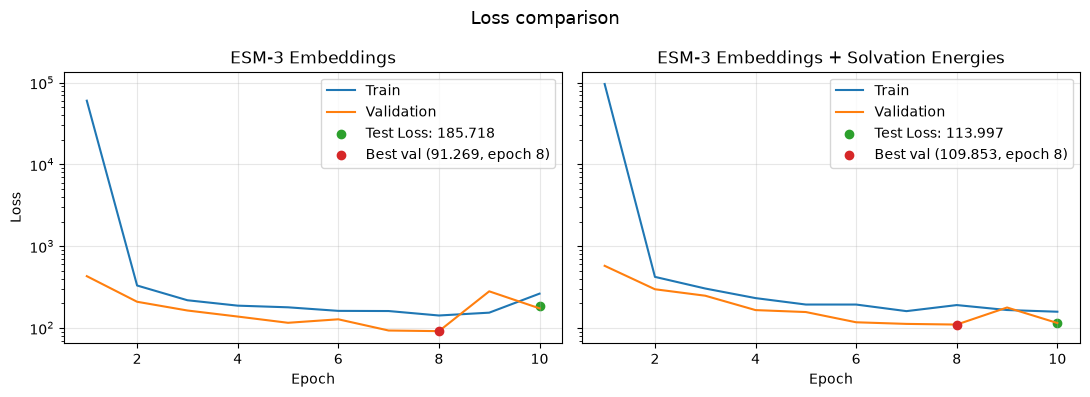

In [3]:
loss_dict_esm3 = compare(embeddings('esm3'), fa_sol_inputs, fa_atr_inputs, "ESM-3")

torch.Size([942, 1])


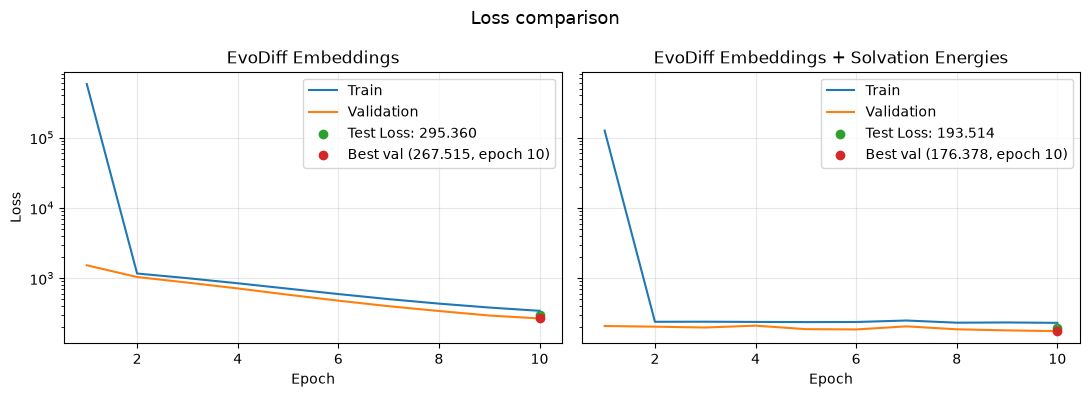

In [4]:
loss_dict_evodiff = compare(embeddings('evodiff'), fa_sol_inputs, fa_atr_inputs, "EvoDiff")

torch.Size([942, 1])


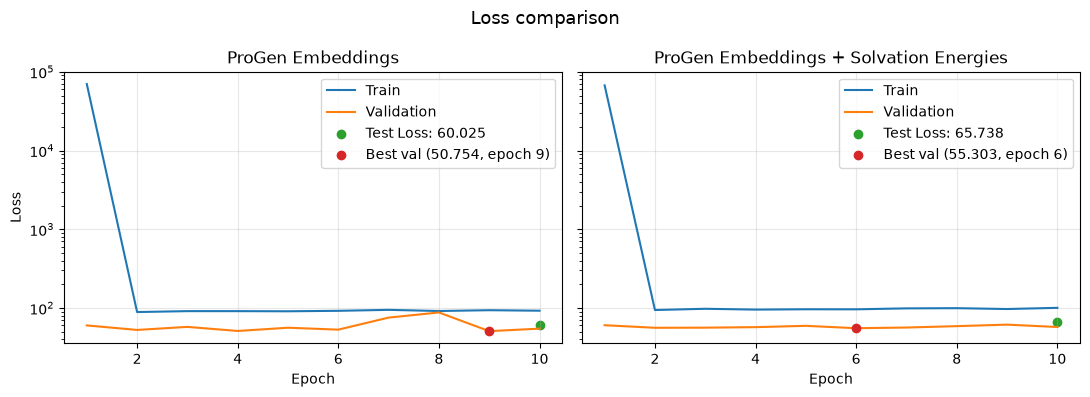

In [5]:
loss_dict_progen = compare(embeddings('progen2'), fa_sol_inputs, fa_atr_inputs, "ProGen")

In [13]:
multi_run_esm3 = run_repetitions(embeddings('esm3'), fa_sol_inputs, fa_atr_inputs, "ESM-3", repetitions=30)

Avg. Test Loss ESM-3: 147.287
Stdev ESM-3: 75.208
Avg. Test Loss ESM-3 w/ fa_sol: 171.642
Stdev ESM-3 w/ fa_sol: 115.144


In [14]:
multi_run_evo = run_repetitions(embeddings('evodiff'), fa_sol_inputs, fa_atr_inputs, "EvoDiff", repetitions=30)

Avg. Test Loss EvoDiff: 289.022
Stdev EvoDiff: 48.449
Avg. Test Loss EvoDiff w/ fa_sol: 201.684
Stdev EvoDiff w/ fa_sol: 11.909


In [15]:
multi_run_pro = run_repetitions(embeddings('progen2'), fa_sol_inputs, fa_atr_inputs, "ProGen2", repetitions=30)

Avg. Test Loss ProGen2: 61.570
Stdev ProGen2: 7.254
Avg. Test Loss ProGen2 w/ fa_sol: 70.870
Stdev ProGen2 w/ fa_sol: 9.595


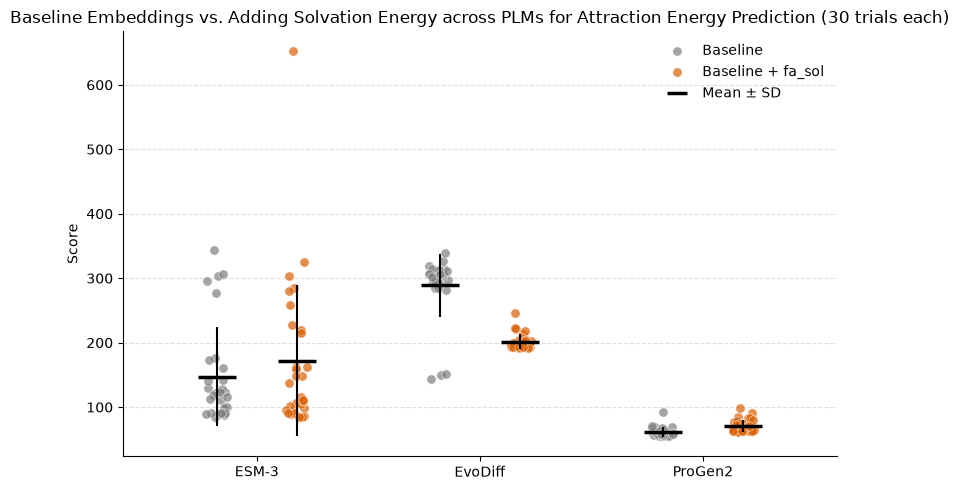

In [16]:
import numpy as np
import matplotlib.pyplot as plt

plms = ["ESM-3", "EvoDiff", "ProGen2"]
rng = np.random.default_rng(42)

data = {
    "EvoDiff": {
        "control": multi_run_evo['test_losses'],
        "experimental": multi_run_evo['test_gfp_losses'],
    },
    "ESM-3": {
        "control": multi_run_esm3['test_losses'],
        "experimental": multi_run_esm3['test_gfp_losses'],
    },
    "ProGen2": {
        "control": multi_run_pro['test_losses'],
        "experimental": multi_run_pro['test_gfp_losses'],
    },
}

# ---------------------------------------------------------------------------
# Plot settings
# ---------------------------------------------------------------------------
colors = {"control": "#7f7f7f", "experimental": "#d95f02"}
offsets = {"control": -0.18, "experimental": 0.18}  # side-by-side placement
jitter = 0.05                                         # horizontal spread of dots

fig, ax = plt.subplots(figsize=(8, 5))

for i, plm in enumerate(plms):
    for condition in ("control", "experimental"):
        values = data[plm][condition]
        x_center = i + offsets[condition]
        x = x_center + rng.uniform(-jitter, jitter, size=len(values))

        # individual trials
        ax.scatter(
            x, values,
            s=45, alpha=0.7, color=colors[condition],
            edgecolor="white", linewidth=0.5, zorder=3,
            label=("Baseline" if condition == 'control' else 'Baseline + fa_sol') if i==0 else None,
        )

        # mean marker with std error bar
        ax.errorbar(
            x_center, values.mean(), yerr=values.std(ddof=1),
            fmt="_", markersize=28, markeredgewidth=2.5,
            color="black", capsize=0, elinewidth=1.5, zorder=4,
        )

ax.set_xticks(range(len(plms)))
ax.set_xticklabels(plms)
ax.set_xlim(-0.6, len(plms) - 0.4)
ax.set_ylabel("Score")
ax.set_title("Baseline Embeddings vs. Adding Solvation Energy across PLMs for Attraction Energy Prediction (30 trials each)")
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.spines[["top", "right"]].set_visible(False)

# add a legend entry explaining the black bars
ax.plot([], [], color="black", marker="_", markersize=14,
        markeredgewidth=2.5, linestyle="none", label="Mean ± SD")
ax.legend(frameon=False, loc="best")

plt.tight_layout()
# plt.savefig("plm_dot_plot.png", dpi=200)
plt.show()